<a href="https://colab.research.google.com/github/jyryu3161/2026CADD/blob/main/week11_synllama_hit_expansion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

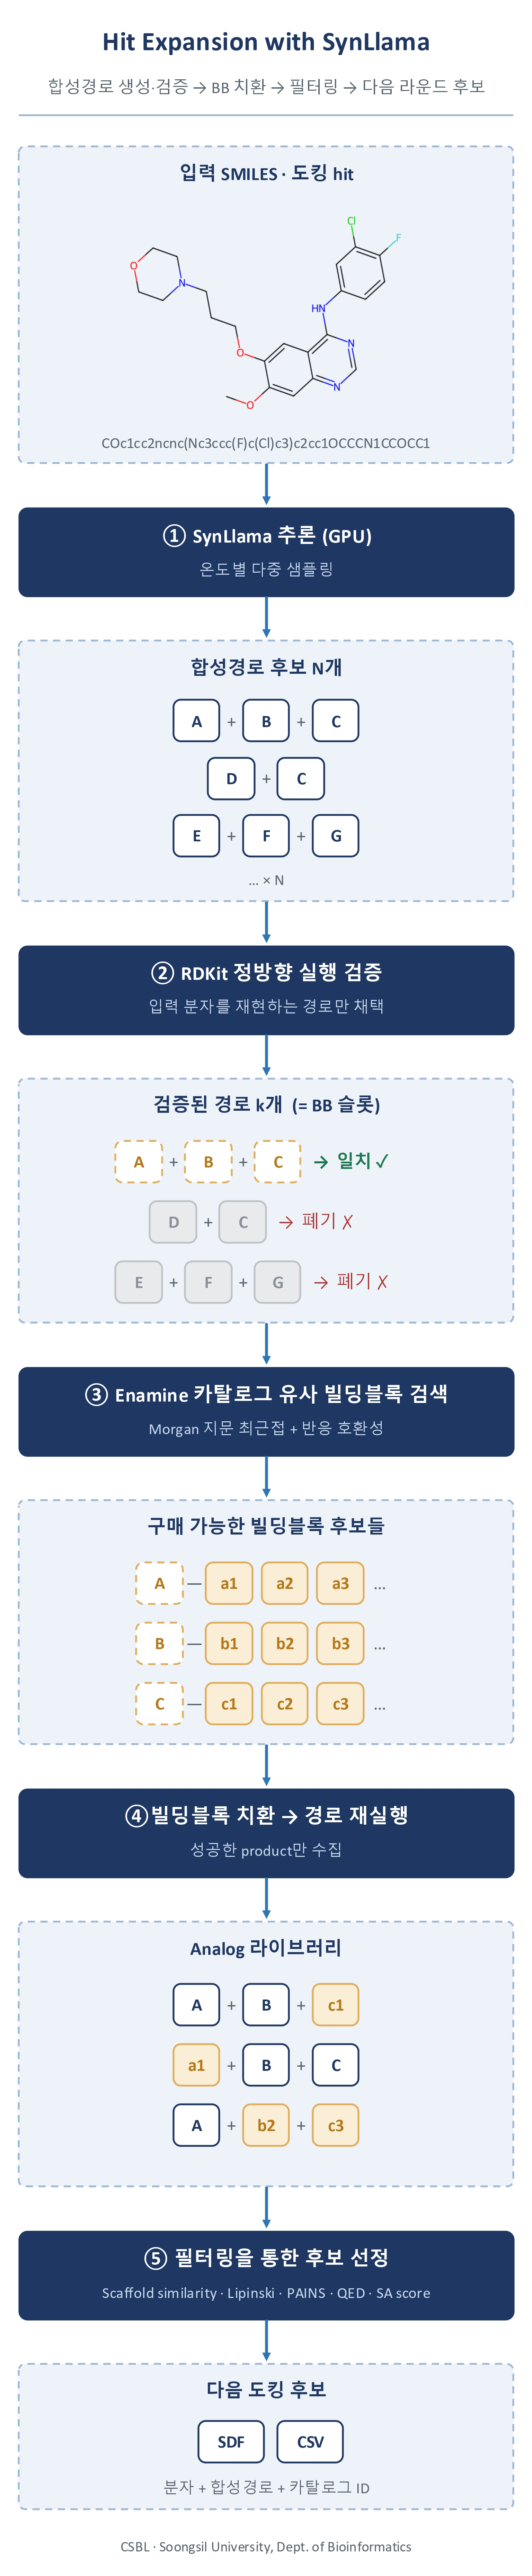

### 이 실습에서 배우는 것

1. **SynLlama로 입력 분자의 합성경로를 역설계**합니다 (SMILES → 반응 템플릿 + building block).
2. 그 경로의 **building block을 실제 Enamine 카탈로그로 치환**해 analog 라이브러리를 만듭니다.
3. **골격 유지 · 물성 · 합성난이도**로 걸러 다음 라운드에 도킹할 후보를 고릅니다.

### 예상 소요 시간


| 단계 | 대략 시간 | 병목 |
|---|---|---|
| 설치 (rdkit + repo) | 1–2 분 | 네트워크 |
| 모델 다운로드 (2.5 GB, 최초 1회) | 2–4 분 | 네트워크 |
| SynLlama 추론 (17 샘플) | 2–5 분 | **GPU** |
| Enamine 카탈로그 지문 인덱스 구축 | 1–4 분 (최초 1회, 캐시됨) | CPU |
| Analog 열거 + 채점 | 10–60 초 | CPU (RDKit) |

### 실습 전 확인 사항
① **런타임 > 런타임 유형 변경 > T4 GPU** 를 선택하세요.

② 나눠드린 Enamine building block CSV를 아래와 같이 파일에 올려두세요.

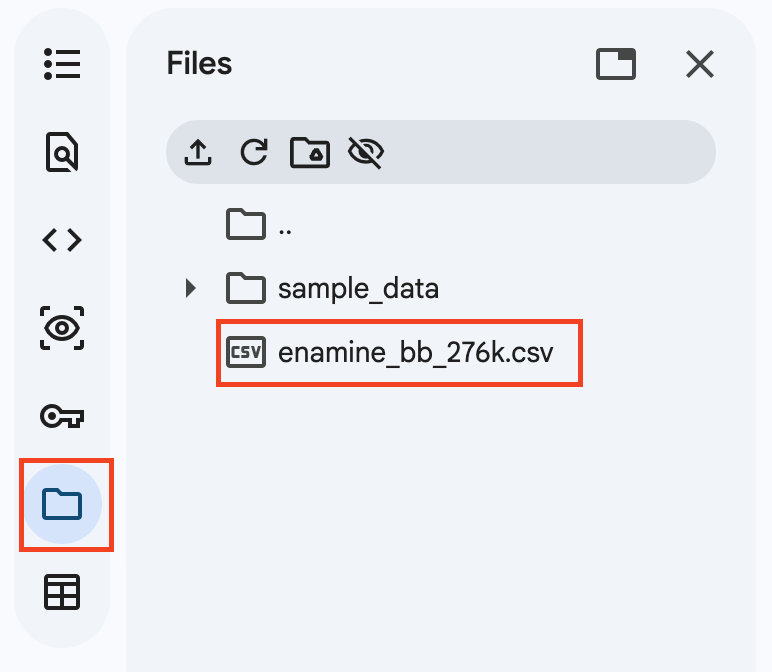

In [ ]:
#@title 0. GPU / 런타임 확인
import subprocess, sys, platform
print("Python :", sys.version.split()[0])
print("Platform:", platform.platform())
try:
    out = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=name,memory.total,driver_version",
         "--format=csv,noheader"], text=True).strip()
    print("GPU    :", out)
except Exception:
    print("GPU    : 감지되지 않음 (CPU로도 동작하지만 추론이 매우 느립니다)")
    print("         Colab 메뉴: Runtime > Change runtime type > T4 GPU")

Python : 3.13.15
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
GPU    : Tesla T4, 15360 MiB, 580.82.07


In [ ]:
#@title 1. 실습 설정

#@markdown ### 입력 — 도킹으로 고른 hit의 SMILES
QUERY_SMILES = "COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1"  #@param {type:"string"}

#@markdown ### SynLlama 추론 — 온도별 샘플 수 (SynLlama 논문의 greedy 모드 기준)
N_FROZEN = 1   #@param {type:"slider", min:0, max:4, step:1}
N_LOW    = 4   #@param {type:"slider", min:0, max:12, step:1}
N_MEDIUM = 6   #@param {type:"slider", min:0, max:12, step:1}
N_HIGH   = 6   #@param {type:"slider", min:0, max:12, step:1}
MAX_NEW_TOKENS = 900  #@param {type:"integer"}

#@markdown ### Enamine 카탈로그 BB 검색
BB_TOPK      = 40   #@param {type:"slider", min:5, max:100, step:5}
BB_PRESELECT = 800  #@param {type:"integer"}
BB_SIM_MIN   = 0.30 #@param {type:"number"}
BB_MW_MAX    = 400  #@param {type:"integer"}
N_DOUBLE_SWAP = 8   #@param {type:"slider", min:0, max:20, step:1}

#@markdown ### Lead optimization 게이트
#@markdown `KEEP_SMARTS`를 비워 두면 **입력 분자의 Murcko 골격 유사도**로 대신 판정합니다

KEEP_SMARTS = ""    #@param {type:"string"}
SCF_SIM_MIN = 0.60  #@param {type:"number"}
SIM_MIN = 0.35  #@param {type:"number"}
SIM_MAX = 0.95  #@param {type:"number"}
N_FINAL = 12    #@param {type:"integer"}
SEED    = 0     #@param {type:"integer"}

MODEL_REPO = "kysun63/synllama-1b-reproduced"   # SynLlama-1B (115 reaction templates)
WORK_DIR   = "/content/leadopt"

# 온도/top_p는 SynLlama 논문의 sampling_params_greedy 값을 그대로 사용한다.
SAMPLING = [
    {"name": "frozen", "temp": 0.1, "top_p": 0.1, "repeat": N_FROZEN},
    {"name": "low",    "temp": 0.6, "top_p": 0.5, "repeat": N_LOW},
    {"name": "medium", "temp": 1.0, "top_p": 0.7, "repeat": N_MEDIUM},
    {"name": "high",   "temp": 1.5, "top_p": 0.9, "repeat": N_HIGH},
]
SAMPLING = [s for s in SAMPLING if s["repeat"] > 0]
print(f"입력 SMILES : {QUERY_SMILES}")
print(f"총 샘플 수  : {sum(s['repeat'] for s in SAMPLING)}")
print(f"작업 폴더   : {WORK_DIR}")

입력 SMILES : COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1
총 샘플 수  : 17
작업 폴더   : /content/leadopt


## 2. 환경 설치

In [ ]:
#@title 2-1. 패키지 설치 + SynLlama 저장소 클론
import os, glob, subprocess, sys, importlib

os.makedirs(WORK_DIR, exist_ok=True)
REPO_DIR = "/content/SynLlama"

def sh(cmd):
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, text=True,
                       stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    if r.returncode != 0:
        print(r.stdout[-2000:])
    return r.returncode

# (1) rdkit
try:
    import rdkit
except ImportError:
    sh("pip install -q rdkit")
    importlib.invalidate_caches()
    import rdkit

# (2) SynLlama 저장소 (chem 유틸: Reaction / Stack / Molecule)
if not os.path.isdir(REPO_DIR):
    sh(f"git clone -q https://github.com/THGLab/SynLlama.git {REPO_DIR}")
sh(f"pip install -q -e {REPO_DIR}")          # 실패해도 아래 sys.path로 대체됨
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

# (3) 그림의 한글 라벨용 폰트 (없으면 matplotlib에서 글자가 □로 깨진다)
if not glob.glob("/usr/share/fonts/**/Nanum*", recursive=True):
    sh("apt-get -qq install -y fonts-nanum > /dev/null 2>&1")

import rdkit, torch, transformers
print("\nrdkit       :", rdkit.__version__)
print("torch       :", torch.__version__, "| CUDA:", torch.cuda.is_available())
print("transformers:", transformers.__version__)

$ pip install -q rdkit
$ git clone -q https://github.com/THGLab/SynLlama.git /content/SynLlama
$ pip install -q -e /content/SynLlama
$ apt-get -qq install -y fonts-nanum > /dev/null 2>&1

rdkit       : 2026.03.6
torch       : 2.11.0+cu128 | CUDA: True
transformers: 5.16.1


In [ ]:
#@title 2-2. import & 공용 유틸
import json, time, itertools, random, warnings
import numpy as np
import pandas as pd
from rdkit import Chem, RDLogger, DataStructs, RDConfig
from rdkit.Chem import (AllChem, Draw, Descriptors, Crippen, QED,
                        rdMolDescriptors, rdChemReactions, rdFingerprintGenerator,
                        FilterCatalog)
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.SimDivFilters.rdSimDivPickers import MaxMinPicker
RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore")
try:                                    # 노트북에서 구조가 바로 그려지게 한다
    from rdkit.Chem.Draw import IPythonConsole
    IPythonConsole.molSize = (350, 300)
except ImportError:
    pass
random.seed(SEED); np.random.seed(SEED)

# SynLlama 내부 모듈: 반응 실행(Reaction) + 경로 스택(Stack) + 지문(Molecule)
from synllama.chem.mol import Molecule, FingerprintOption
from synllama.chem.reaction import Reaction
from synllama.chem.stack import Stack
from synllama.llm.vars import TEMPLATE            # 학습 때 쓴 프롬프트 템플릿

# 합성난이도 점수 (RDKit Contrib)
sys.path.append(os.path.join(RDConfig.RDContribDir, "SA_Score"))
try:
    import sascorer
    HAS_SA = True
except Exception as e:
    HAS_SA = False
    print("[경고] sascorer 사용 불가 →", e)

FPO = FingerprintOption.morgan_for_tanimoto_similarity()   # Morgan r2, 4096 bit
_lfc = rdMolStandardize.LargestFragmentChooser()

def clean(smi):
    """SMILES 정규화: 파싱 실패/빈 값은 None, 염(salt)은 가장 큰 조각만 남긴다."""
    if not smi or not isinstance(smi, str):
        return None
    m = Chem.MolFromSmiles(smi)
    if m is None:
        return None
    m = _lfc.choose(m)
    if m is None or m.GetNumAtoms() == 0:
        return None
    return Chem.MolToSmiles(m)

def tanimoto(a, b):
    """두 SMILES의 Morgan Tanimoto 유사도 (SynLlama 논문과 동일한 지문 설정)."""
    ca, cb = clean(a), clean(b)
    if ca is None or cb is None:
        return float("nan")
    return Molecule(ca).sim(Molecule(cb), FPO)

def scaffold_sim(a, b):
    """Bemis-Murcko 골격끼리의 Tanimoto (step_31의 scf_sim과 동일한 정의)."""
    ca, cb = clean(a), clean(b)
    if ca is None or cb is None:
        return float("nan")
    try:
        return Molecule(ca).scaffold.tanimoto_similarity(Molecule(cb).scaffold, fp_option=FPO)
    except Exception:
        return float("nan")

QUERY = clean(QUERY_SMILES)
assert QUERY, "QUERY_SMILES를 파싱할 수 없습니다."
print("공용 함수 로딩 완료")

공용 함수 로딩 완료


MW 446.9 | cLogP 4.28 | TPSA 68.7 | HBD 1 | HBA 7 | QED 0.518
KEEP_SMARTS  : c1ccc(Nc2ncnc3ccc(OCCCN4CCOCC4)cc23)cc1 
Scaffold 유사도 >= 0.6 로 판정합니다


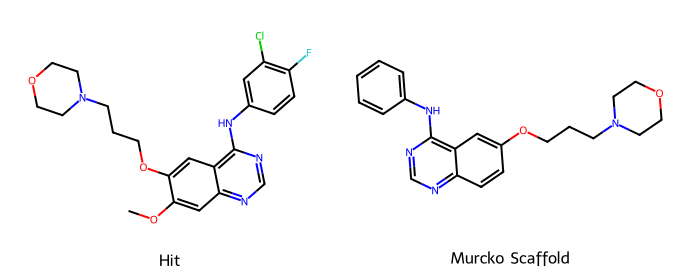

In [ ]:
#@title 3. 입력 분자 확인 (구조 · 물성 · Murcko Scaffold)
qm = Chem.MolFromSmiles(QUERY)
q_scaffold = MurckoScaffold.GetScaffoldForMol(qm)
q_scf_smi = Chem.MolToSmiles(q_scaffold) if q_scaffold.GetNumAtoms() else ""

print(f"MW {Descriptors.MolWt(qm):.1f} | cLogP {Crippen.MolLogP(qm):.2f} | "
      f"TPSA {rdMolDescriptors.CalcTPSA(qm):.1f} | HBD {rdMolDescriptors.CalcNumHBD(qm)} | "
      f"HBA {rdMolDescriptors.CalcNumHBA(qm)} | QED {QED.qed(qm):.3f}")

KEEP_QUERY = Chem.MolFromSmarts(KEEP_SMARTS) if KEEP_SMARTS.strip() else None
if KEEP_QUERY is not None:
    ok = qm.HasSubstructMatch(KEEP_QUERY)
    print(f"KEEP_SMARTS  : {KEEP_SMARTS}  → 입력 분자가 만족하는가: {ok}")
    assert ok, "KEEP_SMARTS가 입력 분자와 맞지 않습니다. 패턴을 확인하세요."
else:
    print(f"KEEP_SMARTS  : {q_scf_smi} \nScaffold 유사도 >= {SCF_SIM_MIN} 로 판정합니다")
USE_SCAFFOLD_GATE = (KEEP_QUERY is None) and bool(q_scf_smi)
if KEEP_QUERY is None and not q_scf_smi:
    print("\n[주의] 입력 분자에 고리가 없어 골격 게이트를 쓸 수 없습니다 → 골격 조건은 생략됩니다.")

Draw.MolsToGridImage([qm, q_scaffold] if q_scf_smi else [qm], molsPerRow=2,
                     subImgSize=(340, 280),
                     legends=["Hit", "Murcko Scaffold"][: 2 if q_scf_smi else 1])

## 4. SynLlama 모델 준비

In [ ]:
#@title 4-1. 모델 다운로드 & 로드 (2.5 GB, 최초 1회)
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

t0 = time.time()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE  = torch.float16 if DEVICE == "cuda" else torch.float32

tokenizer = AutoTokenizer.from_pretrained(MODEL_REPO)
model = AutoModelForCausalLM.from_pretrained(MODEL_REPO, torch_dtype=DTYPE).to(DEVICE)
model.eval()
model.config.use_cache = True          # ★ 체크포인트 기본값(False)을 되돌린다
STOP_IDS = [tokenizer.eos_token_id, tokenizer.convert_tokens_to_ids("<|eot_id|>")]

n_par = sum(p.numel() for p in model.parameters()) / 1e9
print(f"\n로드 완료: {n_par:.2f} B 파라미터 | {DEVICE} / {DTYPE} | {time.time()-t0:.0f}s")
if DEVICE == "cuda":
    print(f"GPU 메모리 점유: {torch.cuda.memory_allocated()/2**30:.2f} GiB")

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.6k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.47GB            

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]


로드 완료: 1.24 B 파라미터 | cuda / torch.float16 | 63s
GPU 메모리 점유: 2.30 GiB


In [ ]:
#@title 4-2. 프롬프트 확인 — 모델이 실제로 보는 입력
def build_prompt(smiles):
    """SynLlama 학습 포맷(alpaca)과 정확히 동일하게 프롬프트를 만든다."""
    inp = TEMPLATE["input"].replace("SMILES_STRING", smiles)
    return ("### Instruction:\n" + TEMPLATE["instruction"]
            + "\n\n### Input:\n" + inp + "\n\n### Response: \n")

prompt = build_prompt(QUERY)
print(prompt)

### Instruction:
You are an expert synthetic organic chemist. Your task is to design a synthesis pathway for a given target molecule using common and reliable reaction templates and building blocks. Follow these instructions:

1. **Input the SMILES String:** Read in the SMILES string of the target molecule and identify common reaction templates that can be applied.

2. **Decompose the Target Molecule:** Use the identified reaction templates to decompose the target molecule into different intermediates.

3. **Check for Building Blocks:** For each intermediate:
   - Identify if it is a building block. If it is, wrap it in <bb> and </bb> tags and save it for later use.
   - If it is not a building block, apply additional reaction templates to further decompose it into building blocks.

4. **Document Reactions:** For each reaction documented in the output, wrap the reaction template in <rxn> and </rxn> tags.

5. **Repeat the Process:** Continue this process until all intermediates are deco

## 5. 합성경로 생성 (① 단계)

여기서 온도를 여러 개 쓰는 이유가 lead optimization의 핵심입니다.

- **낮은 온도(0.1)**: 모델이 가장 확신하는 경로 1개.
- **높은 온도(1.5)**: 같은 분자에 대한 **다른 전략**. 절단 위치가 달라지면
  **BB 슬롯이 달라지고**, 그러면 **다양화할 수 있는 지점이 달라집니다**.

같은 입력에서 서로 다른 경로를 여러 개 얻어야 analog 다양성 확보가 가능합니다.

In [ ]:
#@title 5-1. SynLlama 추론 — 온도별 다중 샘플링
@torch.no_grad()
def generate_routes(smiles, sampling=None, max_new_tokens=None, verbose=True):
    """target SMILES 하나에 대해 합성경로 JSON 후보들을 생성한다."""
    sampling = sampling or SAMPLING
    max_new_tokens = max_new_tokens or MAX_NEW_TOKENS
    enc = tokenizer(build_prompt(smiles), return_tensors="pt").to(model.device)
    plen = enc.input_ids.shape[1]
    raw = []
    for p in sampling:
        out = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=True,
                             temperature=p["temp"], top_p=p["top_p"],
                             num_return_sequences=p["repeat"],
                             eos_token_id=STOP_IDS,
                             pad_token_id=tokenizer.eos_token_id)
        for o in out:
            raw.append({"mode": p["name"], "temp": p["temp"],
                        "text": tokenizer.decode(o[plen:], skip_special_tokens=True).strip()})
        if verbose:
            print(f"  {p['name']:6s} (T={p['temp']}) x{p['repeat']} 완료")
    return raw

def parse_routes(raw):
    """출력 문자열을 JSON으로 파싱. 형식이 깨진 샘플은 버린다."""
    ok, bad = [], 0
    for r in raw:
        try:
            j = json.loads(r["text"])
        except json.JSONDecodeError:
            bad += 1
            continue
        if "reactions" in j and "building_blocks" in j:
            ok.append({**r, "route": j})
        else:
            bad += 1
    return ok, bad

t0 = time.time()
print("합성경로 생성 중...")
raw_outputs = generate_routes(QUERY)
parsed, n_bad = parse_routes(raw_outputs)
print(f"\n생성 {len(raw_outputs)}개 | JSON 유효 {len(parsed)}개 | 깨짐 {n_bad}개"
      f" | {time.time()-t0:.0f}s")

합성경로 생성 중...


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


  frozen (T=0.1) x1 완료
  low    (T=0.6) x4 완료
  medium (T=1.0) x6 완료
  high   (T=1.5) x6 완료

생성 17개 | JSON 유효 17개 | 깨짐 0개 | 71s


In [ ]:
#@title 5-2. 생성된 경로 하나 들여다보기
r0 = parsed[0]["route"]
print(f"[{parsed[0]['mode']} 샘플]  반응 {len(r0['reactions'])}단계, "
      f"building block {len(r0['building_blocks'])}개\n")
print(json.dumps(r0, indent=1, ensure_ascii=False)[:1800])

[frozen 샘플]  반응 3단계, building block 3개

{
 "reactions": [
  {
   "reaction_number": 1,
   "reaction_template": "<rxn>[NH2:1]-[c:2][c:3]-[C:4]#[N:5].[#6;!$(C=[O,S,N]):6][NH2:7]>>[#6:6][NH:7][cH0+0:4]1[nH0+0:5][cH0+0][nH0+0:1][c:2][c:3]1</rxn>",
   "reactants": [
    "",
    "COc1cc(N)c(C#N)cc1OCCCN1CCOCC1",
    "Nc1ccc(F)c(Cl)c1"
   ],
   "product": "COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1"
  },
  {
   "reaction_number": 2,
   "reaction_template": "<rxn>[#6;!$(C=[O,S,N]):1][OH,SH:2].[Cl,Br,I][#6;!$(C=[N,O,S]):3]>>[#6:1][O,S:2][#6:3]</rxn>",
   "reactants": [
    "",
    "COc1cc(N)c(C#N)cc1Br",
    "OCCCN1CCOCC1"
   ],
   "product": "COc1cc(N)c(C#N)cc1OCCCN1CCOCC1"
  },
  {
   "reaction_number": 3,
   "reaction_template": "<rxn>[Cl,Br,I][C$(C([CX4,c])([CX4,c])([CX4,c])),C$([CH]([CX4,c])([CX4,c])),C$([CH2]([CX4,c])),C$([CH3]),c$(c):1]>>[N]#[C][#6:1]</rxn>",
   "reactants": [
    "",
    "",
    "COc1cc(N)c(Br)cc1Br"
   ],
   "product": "COc1cc(N)c(C#N)cc1Br"
  }
 ],
 "building_bloc

## 6. 경로 검증 (② 단계) — **LLM Hallucination 확인**

LLM이 출력한 합성경로를 **RDKit으로 정방향 실행**해서 합성 경로가 실제로 재현되는지 확인합니다.

In [ ]:
#@title 6-1. 경로 정방향 실행기
def bbs_of(route):
    """<bb>...</bb> 태그를 벗겨 building block SMILES 리스트를 얻는다."""
    return [b.split("<bb>")[-1].split("</bb>")[0]
            for b in route.get("building_blocks", []) if isinstance(b, str)]

def tmpl_of(rx):
    """<rxn>...</rxn> 태그를 벗겨 반응 SMARTS를 얻는다."""
    return rx["reaction_template"].split("<rxn>")[1].split("</rxn>")[0]

def execute_route(route, sub=None, product_limit=5):
    """
    합성경로를 RDKit으로 정방향 실행한다.
      route : SynLlama가 낸 JSON
      sub   : {원래 BB SMILES: 치환할 SMILES}  ← analog 생성의 핸들
    반환 : 성공 시 Stack (stack[-1]이 최종 product), 실패 시 None
    """
    sub = sub or {}
    bbs = bbs_of(route)
    rxs = route.get("reactions")
    if not rxs or not bbs:
        return None
    stack = Stack()
    for i, rx in enumerate(rxs[::-1]):                 # retro → forward
        if "reaction_template" not in rx or "reactants" not in rx:
            return None
        try:
            rxn = Reaction(tmpl_of(rx))
            need = rxn.num_reactants
        except Exception:
            return None
        # 이 단계에서 새로 투입되는 것 = building block인 reactant (빈 슬롯 "" 은 패딩)
        slots = [s for s in rx["reactants"] if s and s in bbs]
        expect = need if len(stack) == 0 else need - 1   # 첫 단계 외엔 중간체 1개가 이미 있음
        if len(slots) != expect:
            return None
        for s in slots:
            c = clean(sub.get(s, s))
            if c is None:
                return None
            stack.push_mol(Molecule(c), 0)
        try:
            ok = stack.push_rxn(rxn, i, product_template=rx.get("product"),
                                product_limit=product_limit)
        except Exception:
            return None
        if not ok:
            return None
    return stack

def route_key(route):
    """반응 템플릿 + 반응물 구성으로 경로의 동일성을 판정 (중복 샘플 제거용)."""
    try:
        return json.dumps({"t": sorted(tmpl_of(x) for x in route["reactions"]),
                           "b": sorted(bbs_of(route)),
                           "r": sorted(tuple(sorted(s for s in x["reactants"] if s))
                                       for x in route["reactions"])},
                          sort_keys=True, default=list)
    except Exception:
        return None

def steps_from_stack(stack):
    """실행된 Stack에서 (반응물 리스트, product) 단계 목록을 정방향으로 뽑아낸다."""
    steps = []
    def walk(node):
        if node.rxn is None:
            return
        for c in node.children:
            walk(c)
        steps.append(([c.mol.smiles for c in node.children], node.mol.smiles))
    walk(stack.get_tree())
    return steps

In [ ]:
#@title 6-2. 입력 분자를 완전히 재현하는 경로만 채택
rows, seen, near_miss = [], {}, 0
for p in parsed:
    st = execute_route(p["route"])
    prod = clean(st[-1].smiles) if st is not None else None
    sim = tanimoto(QUERY, prod) if prod else float("nan")
    exact = (prod == QUERY)
    rows.append(dict(mode=p["mode"], temp=p["temp"],
                     n_rxn=len(p["route"].get("reactions", [])),
                     n_bb=len(bbs_of(p["route"])),
                     executable=st is not None,
                     exact=exact,
                     sim_to_query=np.nan if st is None else round(sim, 3)))
    if exact:
        k = route_key(p["route"])
        if k and k not in seen:
            seen[k] = p["route"]
    elif st is not None and sim > 0.999:
        near_miss += 1

audit = pd.DataFrame(rows)
display(audit.groupby("mode", sort=False).agg(
    샘플=("mode", "size"), 실행가능=("executable", "sum"),
    완전재현=("exact", "sum"), 평균유사도=("sim_to_query", "mean")))

verified = sorted(seen.values(),
                  key=lambda r: (-len(bbs_of(r)), -len(r["reactions"])))
print(f"\n실행 가능 {int(audit.executable.sum())}/{len(audit)} | "
      f"정규화 SMILES 완전 일치 {int(audit.exact.sum())}건 → "
      f"중복 제거 후 **검증된 경로 {len(verified)}개**")
if near_miss:
    print(f"(Tanimoto 1.0이지만 canonical SMILES가 다른 샘플 {near_miss}건은 제외했다)")
for i, r in enumerate(verified):
    print(f"  경로 {i}: {len(r['reactions'])}단계 | BB {len(bbs_of(r))}개 → {bbs_of(r)}")
assert verified, "재현 경로가 없습니다. N_MEDIUM/N_HIGH를 늘려 다시 실행하세요."

,샘플,실행가능,완전재현,평균유사도
mode,,,,
frozen,1,0,0,NaN
low,4,1,0,0.74300
medium,6,4,1,0.80725
high,6,5,4,0.94860



실행 가능 10/17 | 정규화 SMILES 완전 일치 5건 → 중복 제거 후 **검증된 경로 4개**
  경로 0: 3단계 | BB 3개 → ['Nc1ccc(F)c(O)c1', 'COc1cc(N)c(C#N)cc1Br', 'OCCCN1CCOCC1']
  경로 1: 2단계 | BB 2개 → ['COc1cc(N)c(C#N)cc1OCCCN1CCOCC1', 'Nc1ccc(F)c(O)c1']
  경로 2: 1단계 | BB 2개 → ['COc1cc2ncnc(Cl)c2cc1OCCCN1CCOCC1', 'Nc1ccc(F)c(Cl)c1']
  경로 3: 1단계 | BB 2개 → ['COc1cc2ncnc(Cl)c2cc1OCCCN1CCOCC1', 'Fc1ccc(N)cc1Cl']


경로 0: 3단계 | 최종 product == 입력 분자: True

  step 1: COc1cc(N)c(C#N)cc1Br.OCCCN1CCOCC1>>COc1cc(N)c(C#N)cc1OCCCN1CCOCC1
  step 2: Nc1ccc(F)c(O)c1.COc1cc(N)c(C#N)cc1OCCCN1CCOCC1>>COc1cc2ncnc(Nc3ccc(F)c(O)c3)c2cc1OCCCN1CCOCC1
  step 3: COc1cc2ncnc(Nc3ccc(F)c(O)c3)c2cc1OCCCN1CCOCC1>>COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1


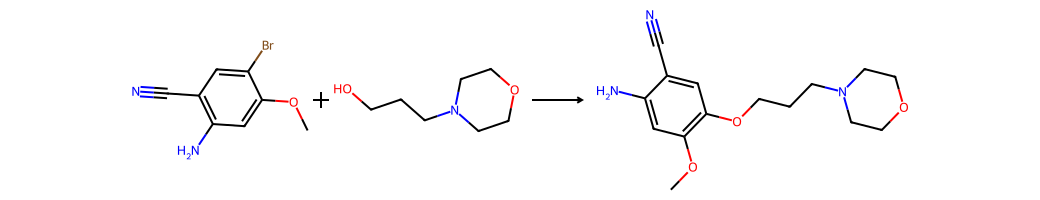

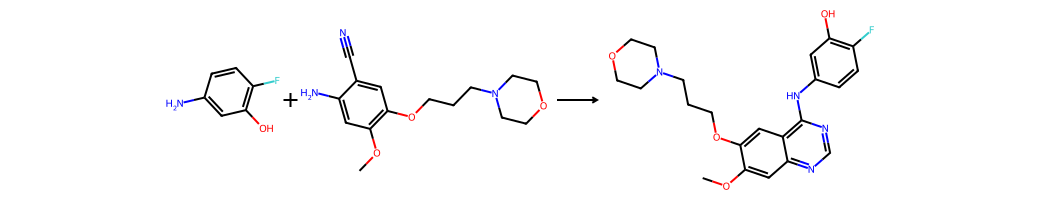

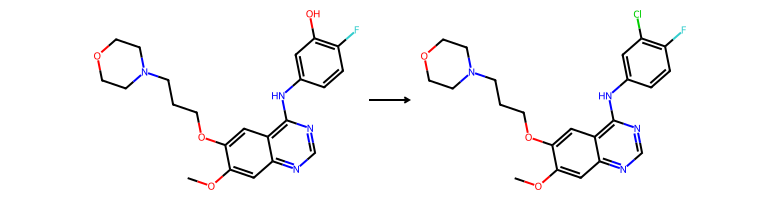

In [ ]:
#@title 6-3. 검증된 경로 1개를 반응 그림으로 보기
ROUTE_TO_DRAW = 0  #@param {type:"integer"}
r = verified[ROUTE_TO_DRAW]
st = execute_route(r)
print(f"경로 {ROUTE_TO_DRAW}: {st.count_reactions()}단계 | "
      f"최종 product == 입력 분자: {clean(st[-1].smiles) == QUERY}\n")
imgs = []
for k, (reactants, product) in enumerate(steps_from_stack(st), 1):
    rxn_smi = ".".join(reactants) + ">>" + product
    print(f"  step {k}: {rxn_smi}")
    imgs.append(rdChemReactions.ReactionFromSmarts(rxn_smi, useSmiles=True))
display(*[Draw.ReactionToImage(x, subImgSize=(260, 200)) for x in imgs])

## 7. Enamine 카탈로그로 Building block 다양화 (③ 단계)

이제 **Building Block 자리마다 대체 후보**를 찾습니다.


### 검색 방식

>**Morgan 지문(256 bit) 최근접**으로 후보를
고르고, **반응 템플릿 호환성 여부**로 한 번 더 거릅니다.<br>
호환성 필터를 통해 뒤 단계에서 반응 실패로 버려지게 되는 문제를 사전에 방지합니다.

In [ ]:
#@title 7-1. 카탈로그 로드 (Drive 또는 로컬)
CATALOG_PATH = "/content/enamine_bb_276k.csv"  #@param {type:"string"}
MOUNT_DRIVE  = True  #@param {type:"boolean"}

if MOUNT_DRIVE and CATALOG_PATH.startswith("/content/drive"):
    try:
        from google.colab import drive
        drive.mount("/content/drive")
    except Exception as e:
        print("Drive 마운트 실패:", e)

if not os.path.exists(CATALOG_PATH):
    print(f"[없음] {CATALOG_PATH}")
    print("Drive에 카탈로그를 올린 뒤 경로를 고치거나, 아래에서 직접 업로드하세요.")
    try:
        from google.colab import files
        up = files.upload()
        CATALOG_PATH = os.path.join("/content", list(up.keys())[0])
    except ImportError:
        raise SystemExit("카탈로그 파일이 필요합니다.")

t0 = time.time()
cat = pd.read_csv(CATALOG_PATH)
cat = cat.dropna(subset=["smiles"]).drop_duplicates(subset=["smiles"]).reset_index(drop=True)
print(f"카탈로그 {len(cat):,}개 로드 | {time.time()-t0:.0f}s")
display(cat.head(3))

[없음] /content/enamine_bb_276k.csv
Drive에 카탈로그를 올린 뒤 경로를 고치거나, 아래에서 직접 업로드하세요.


Saving enamine_bb_276k.csv to enamine_bb_276k (1).csv
카탈로그 276,377개 로드 | 1s


,catalog_id,smiles
0,EN300-07843,CCOc1cc(C=O)ccc1OC(C)C(=O)N(C)C
1,EN300-04783,COc1cc(C=O)ccc1OCC(=O)c1ccc(Cl)c(Cl)c1
2,EN300-04785,Cn1c(NCCO)nc2ccccc21


In [ ]:
#@title 7-2. Morgan 지문 인덱스 구축 (최초 1회, 캐시됨)
#@markdown 카탈로그와 같은 폴더에 `.npz` 캐시를 만들어 두 번째 실행부터는 즉시 로드합니다.
FP_BITS = 256  #@param [128, 256, 512] {type:"raw"}

_stem = CATALOG_PATH[:-3] if CATALOG_PATH.endswith(".gz") else CATALOG_PATH
_stem = _stem[:-4] if _stem.endswith(".csv") else _stem
CACHE_NPZ = f"{_stem}_fp{FP_BITS}.npz"
_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=FP_BITS)
POPC = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint16)

def pack_fp(mol):
    return np.packbits(_gen.GetFingerprintAsNumPy(mol).astype(np.uint8))

if os.path.exists(CACHE_NPZ):
    z = np.load(CACHE_NPZ, allow_pickle=True)
    CAT_FPS, CAT_POP, keep_idx = z["fps"], z["pop"], z["idx"]
    print(f"캐시 로드: {CACHE_NPZ} ({len(CAT_FPS):,}개)")
else:
    t0 = time.time()
    fps, pops, idx = [], [], []
    for i, smi in enumerate(cat.smiles.values):
        m = Chem.MolFromSmiles(smi)
        if m is None:
            continue
        p = pack_fp(m)
        fps.append(p); pops.append(int(POPC[p].sum())); idx.append(i)
        if (i + 1) % 100000 == 0:
            print(f"  {i+1:,} / {len(cat):,}  ({time.time()-t0:.0f}s)")
    CAT_FPS = np.vstack(fps); CAT_POP = np.array(pops, dtype=np.uint16)
    keep_idx = np.array(idx, dtype=np.int64)
    try:
        np.savez_compressed(CACHE_NPZ, fps=CAT_FPS, pop=CAT_POP, idx=keep_idx)
        print(f"캐시 저장: {CACHE_NPZ}")
    except Exception as e:
        print("캐시 저장 실패(무시 가능):", e)
    print(f"지문 {len(CAT_FPS):,}개 | {time.time()-t0:.0f}s")

CAT_SMILES = cat.smiles.values[keep_idx]
CAT_IDS    = cat.catalog_id.fillna("").values[keep_idx]
print(f"검색 대상 {len(CAT_SMILES):,}개 | 지문 {CAT_FPS.shape} "
      f"({CAT_FPS.nbytes/2**20:.0f} MiB)")

def catalog_neighbors(smi, n=None):
    """카탈로그 전체에 대해 Tanimoto를 계산하고 상위 n개의 (인덱스, 유사도)를 준다."""
    n = BB_PRESELECT if n is None else n
    m = Chem.MolFromSmiles(smi)
    if m is None:
        return []
    q = pack_fp(m); qc = int(POPC[q].sum())
    inter = POPC[np.bitwise_and(CAT_FPS, q)].sum(axis=1)
    sims = inter / np.maximum(CAT_POP + qc - inter, 1)
    n = min(n, len(sims))
    top = np.argpartition(-sims, n - 1)[:n]
    top = top[np.argsort(-sims[top])]
    return [(int(i), float(sims[i])) for i in top]

_t = time.time(); _ = catalog_neighbors(QUERY, 50)


  100,000 / 276,377  (16s)
  200,000 / 276,377  (31s)
캐시 저장: /content/enamine_bb_276k (1)_fp256.npz
지문 276,377개 | 45s
검색 대상 276,377개 | 지문 (276377, 32) (8 MiB)


In [ ]:
#@title 7-3. BB 슬롯별 카탈로그 후보 수집
def slot_reactions(route):
    """각 building block이 어떤 반응의 reactant로 쓰였는지 매핑한다."""
    bbs, out = bbs_of(route), {}
    for rx in route["reactions"]:
        try:
            rxn = Reaction(tmpl_of(rx))
        except Exception:
            continue
        for s in rx.get("reactants", []):
            if s and s in bbs:
                out.setdefault(s, []).append(rxn)
    return out

def bb_candidates(bb, rxns, topk=None, sim_min=None, mw_max=None):
    """
    BB 하나에 대한 카탈로그 대체 후보.
      1) Morgan 최근접 BB_PRESELECT개를 뽑고
      2) MW / 유사도 하한으로 자르고
      3) 반응 템플릿 호환성(match_reactant_templates)으로 거른 뒤
      4) 상위 topk개를 남긴다.
    반환: [(smiles, catalog_id, 유사도), ...]
    """
    topk   = BB_TOPK if topk is None else topk
    sim_min = BB_SIM_MIN if sim_min is None else sim_min
    mw_max = BB_MW_MAX if mw_max is None else mw_max
    base = clean(bb)
    keep = []
    for i, s in catalog_neighbors(bb):
        if s < sim_min:
            break
        cs = clean(CAT_SMILES[i])
        if cs is None or cs == base:
            continue
        m = Chem.MolFromSmiles(cs)
        if Descriptors.MolWt(m) > mw_max:
            continue
        if any(len(rx.match_reactant_templates(Molecule(cs))) > 0 for rx in rxns):
            keep.append((cs, CAT_IDS[i], round(s, 3)))
        if len(keep) >= topk:
            break
    return keep

t0 = time.time()
pools, slot_map, CAT_ID_OF = {}, {}, {}
for ri, r in enumerate(verified):
    sr = slot_reactions(r)
    slot_map[ri] = sr
    for bb, rxns in sr.items():
        if bb in pools:
            continue
        cands = bb_candidates(bb, rxns)
        pools[bb] = [c[0] for c in cands]
        for smi, cid, _ in cands:
            CAT_ID_OF[smi] = cid
        print(f"  BB {bb[:44]:44s} → 카탈로그 후보 {len(cands):3d}개"
              + (f" (예: {cands[0][1]} sim {cands[0][2]})" if cands else ""))

print(f"\n다양화 가능 Building Block  {len(pools)}개 | 후보 총 {sum(len(v) for v in pools.values())}개 ")

  BB Nc1ccc(F)c(O)c1                              → 카탈로그 후보  40개 (예: EN300-58853 sim 0.652)
  BB OCCCN1CCOCC1                                 → 카탈로그 후보  40개 (예: EN300-189976 sim 0.905)
  BB COc1cc(N)c(C#N)cc1Br                         → 카탈로그 후보  40개 (예: EN300-46366511 sim 0.733)
  BB COc1cc(N)c(C#N)cc1OCCCN1CCOCC1               → 카탈로그 후보  40개 (예: EN300-184258 sim 0.535)
  BB Nc1ccc(F)c(Cl)c1                             → 카탈로그 후보  40개 (예: EN300-21377 sim 0.65)
  BB COc1cc2ncnc(Cl)c2cc1OCCCN1CCOCC1             → 카탈로그 후보  40개 (예: EN300-23058 sim 0.585)
  BB Fc1ccc(N)cc1Cl                               → 카탈로그 후보  40개 (예: EN300-21377 sim 0.65)

다양화 가능 Building Block  7개 | 후보 총 280개 


## 8. Analog 라이브러리 열거 (④ 단계)

- **1점 치환**: Building Block을 하나만 바꿉니다.
- **2점 치환**: 두 Building Block을 동시에 바꿉니다 → 조합 폭발을 막기 위해 각 슬롯 상위 N개만 사용합니다.

In [ ]:
#@title 8. 치환 조합 열거 → analog 수집
def enumerate_analogs(routes, pools, slot_map, n_double=None, verbose=True):
    n_double = N_DOUBLE_SWAP if n_double is None else n_double
    analogs, n_try = {}, 0

    def record(stack, desc, used):
        p = clean(stack[-1].smiles)
        if p is None or p in analogs:
            return
        analogs[p] = dict(swap=desc, n_steps=stack.count_reactions(),
                          route=stack.get_action_string(),
                          catalog_ids=";".join(sorted({CAT_ID_OF.get(u, "") for u in used}
                                                      - {""})),
                          steps=steps_from_stack(stack))

    for ri, r in enumerate(routes):
        bbs = list(slot_map[ri].keys())
        cand = {b: pools.get(b, []) for b in bbs}
        # ── 1점 치환
        for b, cs in cand.items():
            for c in cs:
                n_try += 1
                st = execute_route(r, {b: c})
                if st is not None:
                    record(st, f"{b} → {c}", [c])
        # ── 2점 치환 (각 슬롯 상위 n_double개만)
        if n_double > 0 and len(bbs) >= 2:
            for b1, b2 in itertools.combinations(bbs, 2):
                for c1 in cand[b1][:n_double]:
                    for c2 in cand[b2][:n_double]:
                        n_try += 1
                        st = execute_route(r, {b1: c1, b2: c2})
                        if st is not None:
                            record(st, f"{b1} → {c1}  +  {b2} → {c2}", [c1, c2])
        if verbose:
            print(f"  경로 {ri} 처리 후 누적 analog: {len(analogs)}")
    return analogs, n_try

t0 = time.time()
analogs, n_try = enumerate_analogs(verified, pools, slot_map)
print(f"\n치환 시도 {n_try}건 → 유효 analog {len(analogs)}개 "
      f"(성공률 {len(analogs)/max(n_try,1):.1%}) | {time.time()-t0:.1f}s")

  경로 0 처리 후 누적 analog: 89
  경로 1 처리 후 누적 analog: 101
  경로 2 처리 후 누적 analog: 193
  경로 3 처리 후 누적 analog: 194

치환 시도 744건 → 유효 analog 194개 (성공률 26.1%) | 1.6s


## 9. Lead optimization 필터 & 랭킹 (⑤ 단계)


**(1) 결합 가설 — 통과/탈락 (필수 게이트)**
- 입력 분자의 **Murcko 골격 유사도 ≥ `SCF_SIM_MIN`** (핵심 Scaffold를 보존하는가?)
- 입력과의 Tanimoto가 `SIM_MIN ~ SIM_MAX` (Hit와 너무 같지도 다르지도 않는가?)

**(2) 약물성 — 통과/탈락**
- Lipinski Ro5, PAINS 구조 경보 제외

**(3) 순위 — 점수화**
- QED(약물유사성), 입력과의 유사도, SA score(합성난이도)의 가중합

In [ ]:
#@title 9-1. 물성 · 골격 · 구조경보 계산
_params = FilterCatalog.FilterCatalogParams()
for _c in (FilterCatalog.FilterCatalogParams.FilterCatalogs.PAINS_A,
           FilterCatalog.FilterCatalogParams.FilterCatalogs.PAINS_B,
           FilterCatalog.FilterCatalogParams.FilterCatalogs.PAINS_C):
    _params.AddCatalog(_c)
PAINS = FilterCatalog.FilterCatalog(_params)

def profile_analogs(analogs, reference=None):
    """어떤 입력 분자에도 적용되는 일반 지표만 쓴다 (분자별 하드코딩 없음)."""
    reference = reference or QUERY
    ref_scf = MurckoScaffold.GetScaffoldForMol(Chem.MolFromSmiles(reference))
    ref_scf_smi = Chem.MolToSmiles(ref_scf) if ref_scf.GetNumAtoms() else ""
    rows = []
    for smi, meta in analogs.items():
        m = Chem.MolFromSmiles(smi)
        if m is None:
            continue
        rows.append(dict(
            smiles=smi,
            sim_to_query=round(tanimoto(reference, smi), 3),
            scf_sim=round(scaffold_sim(reference, smi), 3),
            scf_keep=bool(ref_scf_smi) and m.HasSubstructMatch(ref_scf),
            keep_smarts=(m.HasSubstructMatch(KEEP_QUERY) if KEEP_QUERY is not None else None),
            MW=round(Descriptors.MolWt(m), 1),
            cLogP=round(Crippen.MolLogP(m), 2),
            TPSA=round(rdMolDescriptors.CalcTPSA(m), 1),
            HBD=rdMolDescriptors.CalcNumHBD(m),
            HBA=rdMolDescriptors.CalcNumHBA(m),
            RotB=rdMolDescriptors.CalcNumRotatableBonds(m),
            QED=round(QED.qed(m), 3),
            SA=round(sascorer.calculateScore(m), 2) if HAS_SA else np.nan,
            PAINS=PAINS.HasMatch(m),
            n_steps=meta["n_steps"], catalog_ids=meta["catalog_ids"],
            swap=meta["swap"], route=meta["route"]))
    df = pd.DataFrame(rows)
    df["lipinski_ok"] = ((df.MW <= 500) & (df.cLogP <= 5)
                         & (df.HBD <= 5) & (df.HBA <= 10))
    return df

lib = profile_analogs(analogs)
print(f"analog {len(lib)}개")
print(f"  골격 substructure 유지       : {int(lib.scf_keep.sum())}")
print(f"  골격 유사도 >= {SCF_SIM_MIN}        : {int((lib.scf_sim >= SCF_SIM_MIN).sum())}")
if KEEP_QUERY is not None:
    print(f"  KEEP_SMARTS 만족             : {int(lib.keep_smarts.sum())}")
print(f"  Lipinski 통과                : {int(lib.lipinski_ok.sum())}")
print(f"  PAINS 경보                   : {int(lib.PAINS.sum())}")
display(lib.head(3))

analog 194개
  골격 substructure 유지       : 46
  골격 유사도 >= 0.6        : 111
  Lipinski 통과                : 148
  PAINS 경보                   : 0


,smiles,sim_to_query,scf_sim,scf_keep,keep_smarts,MW,cLogP,TPSA,HBD,HBA,RotB,QED,SA,PAINS,n_steps,catalog_ids,swap,route,lipinski_ok
0,COc1cc2ncnc(Nc3ccc(Cl)c(F)c3)c2cc1OCCCN1CCOCC1,0.877,1.0,True,None,446.9,4.28,68.7,1,7,8,0.518,2.36,False,3,EN300-58853,Nc1ccc(F)c(O)c1 → Nc1ccc(O)c(F)c1,OCCCN1CCOCC1;COc1cc(N)c(C#N)cc1Br;R0_2;COc1cc(...,True
1,COc1cc2ncnc(Nc3ccc(Cl)c(O)c3)c2cc1OCCCN1CCOCC1,0.794,1.0,True,None,444.9,3.84,89.0,2,8,8,0.506,2.42,False,3,EN300-1699476,Nc1ccc(F)c(O)c1 → Nc1ccc(O)c(O)c1,OCCCN1CCOCC1;COc1cc(N)c(C#N)cc1Br;R0_2;COc1cc(...,True
2,COc1cc2ncnc(Nc3ccc(Br)c(Cl)c3)c2cc1OCCCN1CCOCC1,0.821,1.0,True,None,507.8,4.90,68.7,1,7,8,0.435,2.41,False,3,EN300-139538,Nc1ccc(F)c(O)c1 → Nc1ccc(Br)c(O)c1,OCCCN1CCOCC1;COc1cc(N)c(C#N)cc1Br;R0_2;COc1cc(...,False


In [ ]:
#@title 9-2. 게이트 적용 + 점수화
W_QED = 0.4  #@param {type:"number"}
W_SIM = 0.3  #@param {type:"number"}
W_SA  = 0.3  #@param {type:"number"}

def rank_library(df, sim_min=None, sim_max=None):
    sim_min = SIM_MIN if sim_min is None else sim_min
    sim_max = SIM_MAX if sim_max is None else sim_max
    if KEEP_QUERY is not None:
        core_ok = df.keep_smarts.fillna(False)
    elif USE_SCAFFOLD_GATE:
        core_ok = df.scf_sim >= SCF_SIM_MIN
    else:
        core_ok = pd.Series(True, index=df.index)
    q = df[core_ok & ~df.PAINS & df.lipinski_ok
           & df.sim_to_query.between(sim_min, sim_max)].copy()
    sa_term = (10 - q.SA) / 10 if HAS_SA else 0.0
    q["score"] = (W_QED * q.QED + W_SIM * q.sim_to_query + W_SA * sa_term).round(4)
    return q.sort_values("score", ascending=False).reset_index(drop=True)

ranked = rank_library(lib)
print(f"게이트 통과 {len(ranked)} / {len(lib)}개\n")
display(ranked[["smiles", "sim_to_query", "scf_sim", "MW", "cLogP",
                "QED", "SA", "n_steps", "score", "catalog_ids"]].head(15))

게이트 통과 80 / 194개



,smiles,sim_to_query,scf_sim,MW,cLogP,QED,SA,n_steps,score,catalog_ids
0,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCN1CCOCC1,0.905,0.885,432.9,3.89,0.607,2.32,3,0.7447,EN300-19569
1,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCN1CCOC1,0.821,0.786,418.9,3.84,0.625,2.49,3,0.7216,EN300-216139
2,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCN1CCCOCC1,0.851,0.821,446.9,4.28,0.581,2.38,3,0.7163,EN300-2009289
3,Cc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCN1CCOCC1,0.750,0.885,416.9,4.19,0.650,2.34,3,0.7148,EN300-19569;EN300-746616
4,COc1cc2ncnc(Nc3ccc(Cl)c(F)c3)c2cc1OCCN1CCOCC1,0.791,0.885,432.9,3.89,0.607,2.34,3,0.7099,EN300-19569;EN300-58853
5,COc1cc2ncnc(Nc3ccc(F)c(F)c3)c2cc1OCCCN1CCOCC1,0.859,1.000,430.5,3.76,0.546,2.34,1,0.7059,EN300-19934
6,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCC1,0.859,0.830,416.9,4.65,0.539,2.25,3,0.7058,EN300-265437
7,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCCOCC1,0.938,0.926,460.9,4.67,0.490,2.40,3,0.7054,EN300-2009395
8,Fc1ccc(Nc2ncnc3cc(F)c(OCCCN4CCOCC4)cc23)cc1Cl,0.844,1.000,434.9,4.41,0.556,2.39,3,0.7039,EN300-7423528
9,Cc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,0.833,1.000,430.9,4.58,0.554,2.35,3,0.7010,EN300-746616


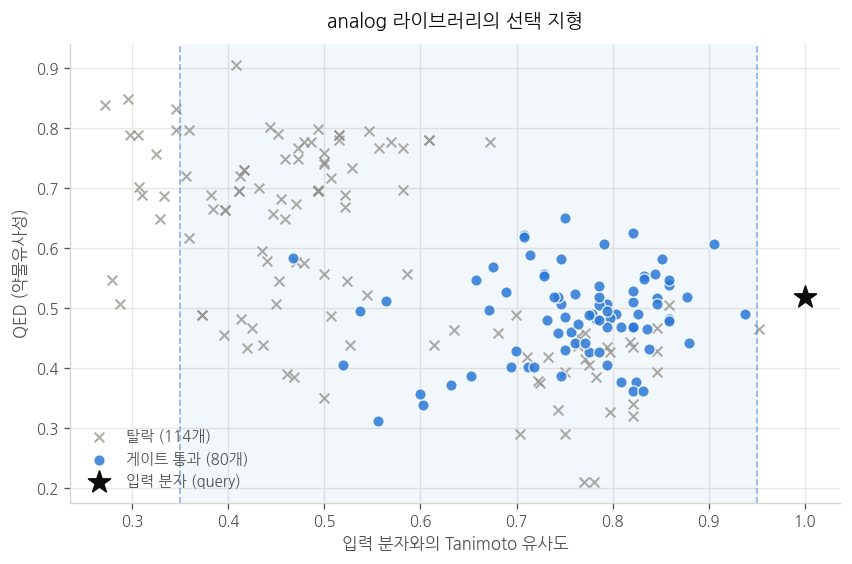

In [ ]:
#@title 9-3. 선택 근거 한 장으로 보기 (유사도 vs 약물유사성)
import glob as _g, matplotlib, matplotlib.pyplot as plt
from matplotlib import font_manager as fm

# 한글 폰트 등록 (Colab: fonts-nanum / 로컬: Noto CJK 등)
for _p in (_g.glob("/usr/share/fonts/**/Nanum*.ttf", recursive=True)
           + _g.glob("/usr/share/fonts/**/NanumGothic*", recursive=True)):
    try:
        fm.fontManager.addfont(_p)
    except Exception:
        pass
_avail = {f.name for f in fm.fontManager.ttflist}
_kor = next((f for f in ("NanumGothic", "NanumBarunGothic", "Noto Sans CJK KR",
                         "Malgun Gothic", "AppleGothic") if f in _avail), None)
if _kor:
    matplotlib.rcParams["font.family"] = _kor
else:
    print("[경고] 한글 폰트를 찾지 못했습니다. 라벨이 □로 보이면 2-1 셀을 다시 실행하세요.")
matplotlib.rcParams["axes.unicode_minus"] = False

PASS_C, FAIL_C = "#2a78d6", "#8f8e87"     # CVD 검증된 2색 (identity는 모양으로도 구분)
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e8e7e2"
PLOT_PATH = os.path.join(WORK_DIR, "selection_landscape.png")

passed = set(ranked.smiles)
gate = lib.smiles.isin(passed)
q_qed = QED.qed(Chem.MolFromSmiles(QUERY))

fig, ax = plt.subplots(figsize=(7.2, 4.8), dpi=120)
fig.patch.set_facecolor("white"); ax.set_facecolor("white")
ax.axvspan(SIM_MIN, SIM_MAX, color=PASS_C, alpha=0.06, lw=0)
for x in (SIM_MIN, SIM_MAX):
    ax.axvline(x, color=PASS_C, ls="--", lw=1, alpha=0.55)
ax.scatter(lib.sim_to_query[~gate], lib.QED[~gate], s=34, marker="x", lw=1.2,
           c=FAIL_C, alpha=0.75, label=f"탈락 ({int((~gate).sum())}개)")
ax.scatter(lib.sim_to_query[gate], lib.QED[gate], s=46, marker="o",
           c=PASS_C, alpha=0.85, edgecolors="white", linewidths=0.8,
           label=f"게이트 통과 ({int(gate.sum())}개)")
ax.scatter([1.0], [q_qed], s=190, marker="*", c=INK, zorder=5, label="입력 분자 (query)")
ax.set_xlabel("입력 분자와의 Tanimoto 유사도", color=INK2, fontsize=10)
ax.set_ylabel("QED (약물유사성)", color=INK2, fontsize=10)
ax.set_title("analog 라이브러리의 선택 지형", color=INK, fontsize=11.5, pad=10)
ax.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
for sp in ("top", "right"):
    ax.spines[sp].set_visible(False)
for sp in ("left", "bottom"):
    ax.spines[sp].set_color("#d6d5cf")
ax.tick_params(colors=INK2, labelsize=9)
ax.legend(frameon=False, fontsize=9, labelcolor=INK2, loc="lower left")
plt.tight_layout()
os.makedirs(WORK_DIR, exist_ok=True)
fig.savefig(PLOT_PATH, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()


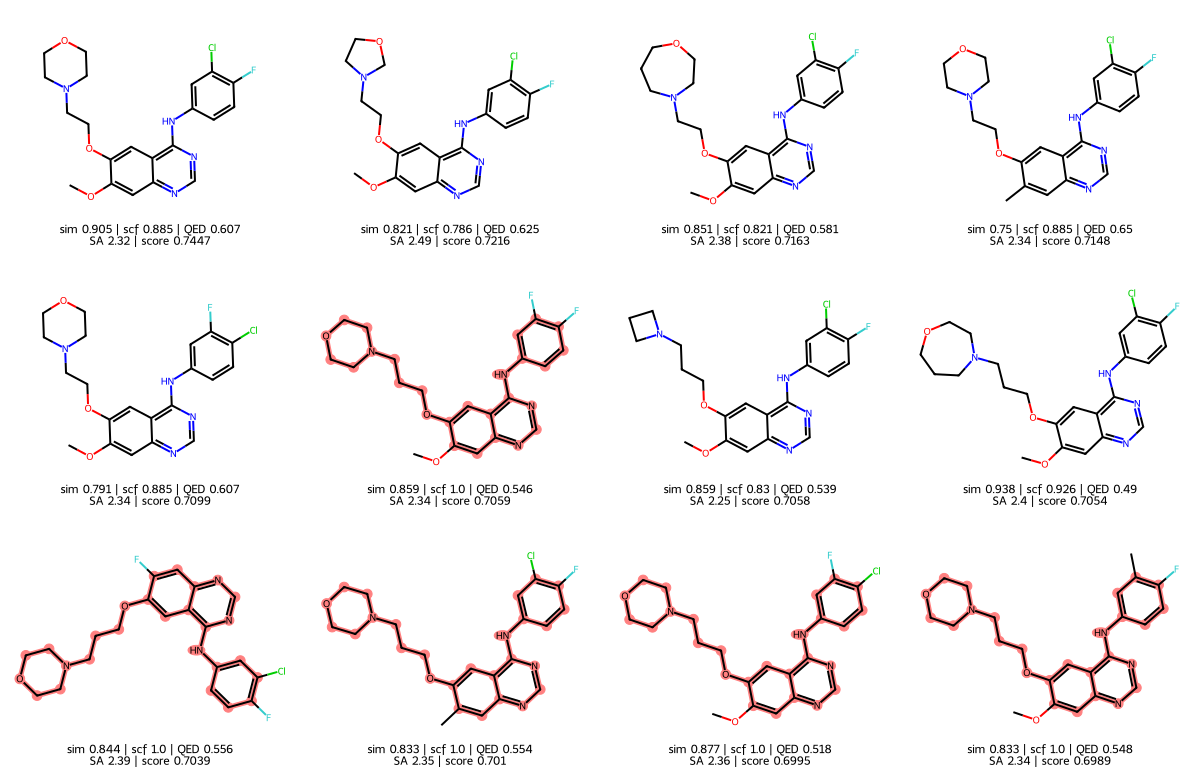

In [ ]:
#@title 9-4. 상위 후보 구조 보기 (입력 골격 하이라이트)
TOP_SHOW = 12  #@param {type:"integer"}
top = ranked.head(TOP_SHOW)
mols = [Chem.MolFromSmiles(s) for s in top.smiles]
hl = [list(m.GetSubstructMatch(q_scaffold)) if q_scf_smi else [] for m in mols]
Draw.MolsToGridImage(
    mols, molsPerRow=4, subImgSize=(300, 260),
    legends=[f"sim {r.sim_to_query} | scf {r.scf_sim} | QED {r.QED}\nSA {r.SA} | score {r.score}"
             for r in top.itertuples()],
    highlightAtomLists=hl)

## 10. 다양성 선정과 export (⑥ 단계)

점수 상위만 뽑으면 **거의 같은 분자**만 나올 수 있습니다. (F→Cl→Br 처럼).<br>
MaxMin picker로 게이트를 통과한 분자 내에서 다양한 분자를 뽑습니다.

최종 후보 12개 (점수 1위 + MaxMin 다양성)



,smiles,sim_to_query,scf_sim,MW,cLogP,QED,SA,score,catalog_ids
0,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCN1CCOCC1,0.905,0.885,432.9,3.89,0.607,2.32,0.7447,EN300-19569
35,COc1cc(OCCCN2CCOCC2)cc2c(Nc3ccc(F)c(Cl)c3)ncnc12,0.743,1.000,446.9,4.28,0.518,2.42,0.6575,EN300-3032628
39,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCCNCC1,0.775,0.733,460.0,4.24,0.488,2.45,0.6542,EN300-26946415
45,COc1cc2ncnc(Nc3ccc(F)c(C(N)=O)c3)c2cc1OCCCN1CC...,0.764,1.000,455.5,2.72,0.474,2.43,0.6459,EN300-35727
50,Cc1cc2ncnc(Nc3ccc(Cl)c(O)c3)c2cc1OCCCN1CCOCC1,0.658,1.000,428.9,4.14,0.547,2.44,0.6430,EN300-1699476;EN300-746616
55,COc1cc2ncnc(NCCc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1,0.761,0.733,475.0,4.19,0.442,2.42,0.6325,EN300-8002130
60,COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCC(C(...,0.743,0.815,487.9,3.41,0.458,2.68,0.6257,EN300-46735221
64,COc1cc2ncnc(NC(C)(C)c3ccc(F)c(Cl)c3)c2cc1OCCCN...,0.750,0.759,489.0,4.88,0.430,2.64,0.6178,EN300-53769982
66,Nc1ccc(F)c(Nc2ccc(OCCCN3CCOCC3)c(F)c2)c1,0.467,0.642,363.4,3.39,0.583,2.18,0.6079,EN300-7472531
72,COc1cc2ncnc(Nc3cc(N)ccc3Cl)c2cc1OCCCN1CCOCC1,0.694,1.000,443.9,3.72,0.402,2.41,0.5967,EN300-19551


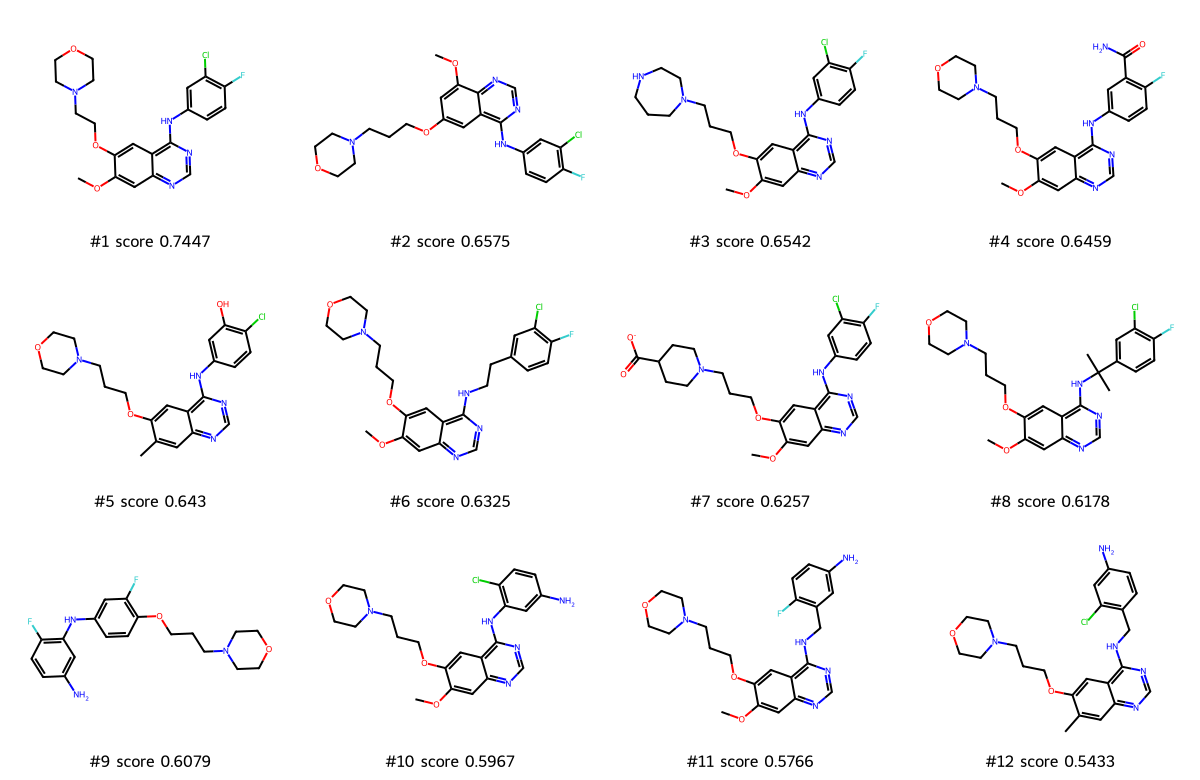

In [ ]:
#@title 10-1. MaxMin 다양성 선정
def pick_diverse(df, n=None, seed=None):
    n = N_FINAL if n is None else n
    seed = SEED if seed is None else seed
    if len(df) <= n:
        return df.copy()
    fps = [AllChem.GetMorganFingerprintAsBitVect(Chem.MolFromSmiles(s), 2, 2048)
           for s in df.smiles]
    def dist(i, j):
        return 1.0 - DataStructs.TanimotoSimilarity(fps[i], fps[j])
    # 점수 1위는 반드시 포함시키고(firstPicks) 나머지를 다양성으로 채운다
    idx = MaxMinPicker().LazyPick(dist, len(fps), n, firstPicks=[0], seed=seed)
    return df.iloc[sorted(idx)].copy()

final = pick_diverse(ranked)
print(f"최종 후보 {len(final)}개 (점수 1위 + MaxMin 다양성)\n")
display(final[["smiles", "sim_to_query", "scf_sim", "MW", "cLogP",
               "QED", "SA", "score", "catalog_ids"]])
mols = [Chem.MolFromSmiles(s) for s in final.smiles]
Draw.MolsToGridImage(mols, molsPerRow=4, subImgSize=(300, 260),
                     legends=[f"#{i+1} score {r.score}"
                              for i, r in enumerate(final.itertuples())])

In [ ]:
#@title 10-2. 결과 파일 생성 (CSV + SDF + 합성경로 텍스트)
os.makedirs(WORK_DIR, exist_ok=True)
csv_path   = os.path.join(WORK_DIR, "candidates.csv")
lib_path   = os.path.join(WORK_DIR, "full_library.csv")
sdf_path   = os.path.join(WORK_DIR, "candidates.sdf")
route_path = os.path.join(WORK_DIR, "routes.txt")

final.to_csv(csv_path, index=False)
lib.to_csv(lib_path, index=False)

# 재도킹 입력용 3D SDF (합성경로·카탈로그 ID를 태그로 붙인다)
w = Chem.SDWriter(sdf_path)
for i, row in enumerate(final.itertuples(), 1):
    m = Chem.AddHs(Chem.MolFromSmiles(row.smiles))
    if AllChem.EmbedMolecule(m, randomSeed=SEED + i) == 0:
        AllChem.MMFFOptimizeMolecule(m, maxIters=500)
    m.SetProp("_Name", f"analog_{i:02d}")
    for k in ("swap", "route", "catalog_ids", "score", "sim_to_query",
              "scf_sim", "QED", "SA", "n_steps"):
        m.SetProp(k, str(getattr(row, k)))
    w.write(m)
w.close()

# 사람이 읽는 합성경로 요약
with open(route_path, "w") as f:
    f.write(f"입력 분자(query): {QUERY}\n")
    f.write(f"카탈로그: {os.path.basename(CATALOG_PATH)} ({len(CAT_SMILES):,}개)\n")
    f.write("=" * 78 + "\n")
    for i, row in enumerate(final.itertuples(), 1):
        f.write(f"\n[analog_{i:02d}] score {row.score} | "
                f"유사도 {row.sim_to_query} | 골격유사도 {row.scf_sim} | {row.n_steps}단계\n")
        f.write(f"  SMILES      : {row.smiles}\n")
        f.write(f"  치환         : {row.swap}\n")
        f.write(f"  카탈로그 ID  : {row.catalog_ids or '(없음)'}\n")
        f.write(f"  합성경로     : {row.route}\n")

for p in (csv_path, lib_path, sdf_path, route_path, PLOT_PATH):
    print(f"  {os.path.basename(p):26s} {os.path.getsize(p)/1024:8.1f} KB")

  candidates.csv                  4.3 KB
  full_library.csv               63.4 KB
  candidates.sdf                 62.5 KB
  routes.txt                      5.3 KB
  selection_landscape.png        89.1 KB


In [ ]:
#@title 10-3. 핵심 결과 ZIP으로 묶어 다운로드
import zipfile, datetime, textwrap

stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M")
zip_path = os.path.join(WORK_DIR, f"synllama_leadopt_{stamp}.zip")
readme_path = os.path.join(WORK_DIR, "README.txt")

with open(readme_path, "w") as f:
    f.write(textwrap.dedent(f"""\
        SynLlama lead optimization 결과
        생성 시각        : {datetime.datetime.now():%Y-%m-%d %H:%M}
        ------------------------------------------------------------------
        입력 분자(query) : {QUERY}
        모델             : {MODEL_REPO}
        카탈로그         : {os.path.basename(CATALOG_PATH)} ({len(CAT_SMILES):,}개)
        추론 샘플        : {len(raw_outputs)} (JSON 유효 {len(parsed)})
        검증된 경로      : {len(verified)} (입력 분자를 정확히 재현)
        analog 총수      : {len(lib)}  → 게이트 통과 {len(ranked)}  → 최종 {len(final)}
        게이트           : 골격유사도>={SCF_SIM_MIN} (KEEP_SMARTS='{KEEP_SMARTS}'),
                           유사도 {SIM_MIN}~{SIM_MAX}, Lipinski, PAINS 제외
        점수식           : {W_QED}*QED + {W_SIM}*유사도 + {W_SA}*(10-SA)/10
        ------------------------------------------------------------------
        candidates.csv          최종 후보 (다양성 선정 후)
        candidates.sdf          재도킹 입력용 3D 구조 + 합성경로 태그
        routes.txt              후보별 합성경로 / 카탈로그 ID
        full_library.csv        필터 전 analog 전체 + 계산된 물성
        selection_landscape.png 선택 지형 그림
        ------------------------------------------------------------------
        주의: 점수는 약물성 대리지표이며 결합력 예측이 아니다.
              후보는 재도킹으로 검증해야 한다.
        """))

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in (readme_path, csv_path, sdf_path, route_path, lib_path, PLOT_PATH):
        if os.path.exists(p):
            z.write(p, arcname=os.path.basename(p))

print(f"ZIP 생성: {zip_path}  ({os.path.getsize(zip_path)/1024:.1f} KB)")
with zipfile.ZipFile(zip_path) as z:
    for i in z.infolist():
        print(f"   {i.filename:26s} {i.file_size/1024:8.1f} KB")

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("\n(Colab이 아니므로 자동 다운로드는 생략됩니다)")

ZIP 생성: /content/leadopt/synllama_leadopt_20260918_1027.zip  (107.5 KB)
   README.txt                      1.2 KB
   candidates.csv                  4.3 KB
   candidates.sdf                 62.5 KB
   routes.txt                      5.3 KB
   full_library.csv               63.4 KB
   selection_landscape.png        89.1 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 참고문헌

- Sun, K.; Bagni, D.; Cavanagh, J. M.; Wang, Y.; Sawyer, J. M.; Zhou, B.; Gritsevskiy, A.;
  Zhang, O.; Head-Gordon, T. **SynLlama: Generating Synthesizable Molecules and Their Analogs
  with Large Language Models.** *ACS Cent. Sci.* **2025**, *11*, 2108–2120.
  doi:[10.1021/acscentsci.5c01285](https://doi.org/10.1021/acscentsci.5c01285)
- 저장소: <https://github.com/THGLab/SynLlama> · 데이터: figshare `39a37d31cea2c190498d`
- 모델(재현본): <https://huggingface.co/kysun63/synllama-1b-reproduced>
- Enamine building blocks: <https://enamine.net/building-blocks>